# Project 1: Classification in Practice
## Predicting Whether a Breast Mass Is Malignant

**Noah Baugh | DATA 201 | Fall 2026**

**The big question:** can measurements taken from a breast mass be used to classify that mass as malignant or benign, and which classifier should we actually trust to do it?

This notebook works through the Wisconsin Diagnostic Breast Cancer dataset. The goal is not the highest accuracy number. A missed cancer and a false alarm are not the same kind of mistake, and most of the analysis below is about that difference.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (7, 4.5)

---
# Part 1: Understand the Problem

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# sklearn codes 0 = malignant and 1 = benign. That is backwards for our purposes.
# We recode so that 1 = malignant, because malignant is the event we are trying to catch
# and every metric below (recall, precision) is defined with respect to the positive class.
df["malignant"] = (df["target"] == 0).astype(int)
df = df.drop(columns=["target"])

print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()

Rows: 569  Columns: 31


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### 1.1 What is represented in each row? What is the response variable?

Every row represents one instance of a breast mass collected through fine needle aspiration from one patient. There are 30 predictors, which correspond to the measurements calculated using the digitized image of the collected sample. For ten basic measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), the three types of measurements are provided: the mean over cell nuclei within the image, standard error, and the maximum values observed.

The response variable is `malignant` which consists of two categories:

- **1 = malignant**: the mass is cancerous
- **0 = benign**: the mass is not cancerous

This is a binary classification task.

In [3]:
print("Predictor columns:", len(df.columns) - 1)
for i, c in enumerate(df.columns[:-1]):
    print(f"  {i+1:2d}. {c}")

Predictor columns: 30
   1. mean radius
   2. mean texture
   3. mean perimeter
   4. mean area
   5. mean smoothness
   6. mean compactness
   7. mean concavity
   8. mean concave points
   9. mean symmetry
  10. mean fractal dimension
  11. radius error
  12. texture error
  13. perimeter error
  14. area error
  15. smoothness error
  16. compactness error
  17. concavity error
  18. concave points error
  19. symmetry error
  20. fractal dimension error
  21. worst radius
  22. worst texture
  23. worst perimeter
  24. worst area
  25. worst smoothness
  26. worst compactness
  27. worst concavity
  28. worst concave points
  29. worst symmetry
  30. worst fractal dimension


### 1.2 Which predictors could be useful?

They all appear to be reasonable predictors because all of them depict either the shape or size of the nuclei, which is the characteristic that pathologists examine. Instead of removing some of the predictors arbitrarily, the test of correlation below indicates which ones distinguish between the two categories.

In [4]:
corr = df.corr()["malignant"].drop("malignant").sort_values(ascending=False)
print("Ten predictors most associated with malignancy:")
print(corr.head(10).round(3).to_string())
print()
print("Ten predictors least associated:")
print(corr.tail(10).round(3).to_string())

Ten predictors most associated with malignancy:
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660

Ten predictors least associated:
mean smoothness            0.359
mean symmetry              0.330
worst fractal dimension    0.324
compactness error          0.293
concavity error            0.254
fractal dimension error    0.078
symmetry error            -0.007
texture error             -0.008
mean fractal dimension    -0.013
smoothness error          -0.067


Worst measurements, such as worst concave points, worst perimeter, worst radius, worst area, and mean concave points, are most correlated with malignancy, with correlations above 0.73. It is not surprising because malignant tumors usually have larger and more irregular nuclei, and thus, the largest nucleus among all contains more information than the average one.

A few predictors contain virtually no information. The correlation between mean fractal dimension and the class is about 0.01. Columns of standard errors for texture, smoothness, and symmetry are almost zero.

**Decision: use all 30 predictors.** Removing them does not simplify the model substantially and can lead to loss of important information contained in some predictors in interaction with others. All four classifiers can deal with 30 predictors and 426 rows easily.

Class counts
  Benign    (0): 357  (62.7%)
  Malignant (1): 212  (37.3%)

Total: 569 observations


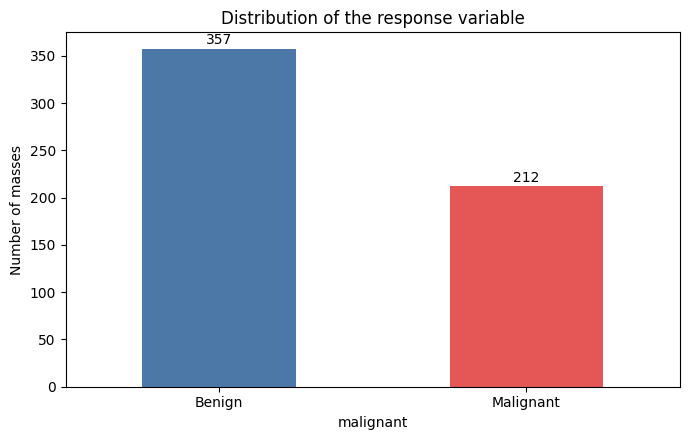

In [5]:
counts = df["malignant"].value_counts().sort_index()
print("Class counts")
print(f"  Benign    (0): {counts[0]}  ({counts[0]/len(df):.1%})")
print(f"  Malignant (1): {counts[1]}  ({counts[1]/len(df):.1%})")
print(f"\nTotal: {len(df)} observations")

ax = counts.plot(kind="bar", color=["#4C78A8", "#E45756"])
ax.set_xticklabels(["Benign", "Malignant"], rotation=0)
ax.set_ylabel("Number of masses")
ax.set_title("Distribution of the response variable")
for i, v in enumerate(counts):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.show()

### 1.3 Is the dataset balanced?

With 357 benign and 212 malignant masses, malignant masses make up 37.3% of the data set. The dataset is **slightly unbalanced but not highly so**. There are sufficient cases of malignancies that a classifier will be able to detect the pattern even without special techniques such as resampling or weighing classes.

This is relevant to interpreting the results. A model that classified each and every mass as benign would have 62.7% accuracy with no cancer being detected at all. This shows that accuracy is not an appropriate metric for assessing the effectiveness of a classifier in this situation.

### 1.4 False positive and false negative in context

- **False positive:** the model identifies the mass as malignant when in reality it is benign. Practically, it means the woman is diagnosed with cancer, while she doesn’t have one. This implies a need for additional tests such as biopsy, spending money and experiencing stress.

- **False negative:** the model classifies the mass as benign when in reality it is malignant. This means the cancer will be undiagnosed, while the woman will be discharged from the hospital. In this case, the result will be late diagnosis and late treatment.

### 1.5 Which error is worse?

**False negatives are significantly more serious than false positives in this context, and the difference between them is not subtle.**

A false positive causes an additional test. It is unpleasant and has some costs attached to it, but it is survivable and self-correcting because the biopsy turns out to be negative and the patient feels better about her health. This is the limit of the cost.

A false negative does not correct itself. No part of the process can catch the mistake because the patient was already assured everything is all right and sees no need to come back. The tumor keeps growing while undetected, and the cost accumulates over time.

The importance of the discrepancy is clear from which metric needs to be maximized. **Recall, the proportion of truly malignant masses detected by the classifier, is the important metric for this task**, and we will have to tolerate some false positives to improve it. The accuracy, which assumes both types of mistakes to be equally serious, is obviously wrong.

---
# Part 2: Explore and Prepare the Data

In [6]:
print("=== Missing values ===")
missing = df.isna().sum()
print("Total missing values across all columns:", missing.sum())
print()
print("=== Data types ===")
print(df.dtypes.value_counts())
print()
print("=== Duplicate rows ===")
print("Duplicates:", df.duplicated().sum())

=== Missing values ===
Total missing values across all columns: 0

=== Data types ===
float64    30
int64       1
Name: count, dtype: int64

=== Duplicate rows ===
Duplicates: 0


### 2.2 Missing values

**There are no missing values.** Each of the 569 observations has values for all 31 columns and there are no duplicated rows. Imputation, observation deletion, or indicator column are not needed.

This is an inherent characteristic of this specific dataset, and not something to expect in general case. Data was generated by automated image analysis, and thus all the measurements were done in the same manner for each of the samples. Clinical data obtained manually are always much more messy.

### 2.3 Categorical predictors

**There are none.** All of the 30 predictors are continuous floats because they are all physical measures obtained through the image. One-hot encoding, label encoding, or creation of dummy variables is not necessary.

The target variable is categorical, but it is already encoded in terms of 0 and 1, which is what classifiers will expect anyway.

In [7]:
scale_check = df.drop(columns=["malignant"]).describe().T[["mean", "std", "min", "max"]]
print("Predictors on the largest scale:")
print(scale_check.sort_values("max", ascending=False).head(5).round(3).to_string())
print()
print("Predictors on the smallest scale:")
print(scale_check.sort_values("max").head(5).round(5).to_string())

Predictors on the largest scale:
                    mean      std      min     max
worst area       880.583  569.357  185.200  4254.0
mean area        654.889  351.914  143.500  2501.0
area error        40.337   45.491    6.802   542.2
worst perimeter  107.261   33.603   50.410   251.2
mean perimeter    91.969   24.299   43.790   188.5

Predictors on the smallest scale:
                            mean      std      min      max
fractal dimension error  0.00379  0.00265  0.00089  0.02984
smoothness error         0.00704  0.00300  0.00171  0.03113
concave points error     0.01180  0.00617  0.00000  0.05279
symmetry error           0.02054  0.00827  0.00788  0.07895
mean fractal dimension   0.06280  0.00706  0.04996  0.09744


### 2.5 Should predictors be standardized?

**Yes, and for KNN it is not optional.**

The ranges vary wildly. `worst area` varies up to about 4254 while `mean fractal dimension` reaches at most about 0.097. This is an order of magnitude difference of around five.

The importance of standardization differs depending on classifier:

- **KNN** measures Euclidean distance between the points. Without standardizing, `worst area` adds thousands to the distances, whereas `mean fractal dimension` adds less than one. As a result, the algorithm will be using only the `worst area` and completely ignore most other 29 predictors. Standardization is essential.
- **Logistic Regression** converges much faster and more robustly on the standardized data, and the resulting coefficients can be compared to each other.
- **LDA and QDA** theoretically do not depend on linear scaling of the features due to use of covariance matrix. However, standardization improves their stability.

All models listed above are therefore put into a `Pipeline` with `StandardScaler`. **It is the pipeline that protects us from data leakage.** In case of scaling of the whole dataset prior to splitting, the mean and std of the test fold would leak into the training stage. Within a pipeline, however, the scaler is fit on the train fold and then transforms the held-out one.

In [8]:
X = df.drop(columns=["malignant"])
y = df["malignant"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {len(X_train)} rows")
print(f"Test set:     {len(X_test)} rows")
print()
print(f"Malignant rate in full data: {y.mean():.4f}")
print(f"Malignant rate in training:  {y_train.mean():.4f}")
print(f"Malignant rate in test:      {y_test.mean():.4f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("\nCross-validation: 5-fold stratified, shuffled")

Training set: 426 rows
Test set:     143 rows

Malignant rate in full data: 0.3726
Malignant rate in training:  0.3732
Malignant rate in test:      0.3706

Cross-validation: 5-fold stratified, shuffled


### 2.4 Splitting and Cross Validation

The dataset is divided into 75/25 proportions with 426 train rows and 143 test rows. `stratify=y` makes sure that the proportion of malignancy is almost the same for both datasets, which are 37.3% in train and 37.1% in test. If not for stratification, the random division could lead to having too many maligned instances in one group.

**Test set will be kept separate until Part 4.** Any modeling will be performed using 5-fold cross-validation on train only. Reporting the accuracy on the test set after making modeling decisions on the test set would lead to overfitting the data.

---
# Part 3: Build the Classifiers


In [9]:
logreg = Pipeline([("scaler", StandardScaler()),
                   ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
logreg.fit(X_train, y_train)

logreg_probs = logreg.predict_proba(X_test)[:, 1]
logreg_preds = logreg.predict(X_test)

print("Logistic Regression fitted.")
print(f"Intercept: {logreg.named_steps['model'].intercept_[0]:.4f}")
print()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print("Five largest coefficients by magnitude (on standardized predictors):")
print(coefs.head(5).round(4).to_string())
print()
print("First 10 test predictions and their predicted probabilities of malignancy:")
preview = pd.DataFrame({"predicted_prob": logreg_probs[:10].round(4),
                        "predicted_class": logreg_preds[:10],
                        "actual": y_test.values[:10]})
print(preview.to_string(index=False))

Logistic Regression fitted.
Intercept: -0.2556

Five largest coefficients by magnitude (on standardized predictors):
worst texture          1.3658
radius error           1.2672
worst symmetry         1.0365
mean concave points    0.9630
compactness error     -0.9275

First 10 test predictions and their predicted probabilities of malignancy:
 predicted_prob  predicted_class  actual
         0.9994                1       1
         0.0039                0       0
         0.9997                1       1
         0.0000                0       0
         0.0345                0       0
         0.0036                0       0
         0.0004                0       0
         0.0019                0       0
         0.0069                0       0
         0.0989                0       0


In [10]:
lda = Pipeline([("scaler", StandardScaler()), ("model", LinearDiscriminantAnalysis())])
lda.fit(X_train, y_train)
lda_probs = lda.predict_proba(X_test)[:, 1]
lda_preds = lda.predict(X_test)
print("LDA fitted. Test predictions generated.")

qda = Pipeline([("scaler", StandardScaler()),
                ("model", QuadraticDiscriminantAnalysis(reg_param=0.01))])
qda.fit(X_train, y_train)
qda_probs = qda.predict_proba(X_test)[:, 1]
qda_preds = qda.predict(X_test)
print("QDA fitted. Test predictions generated.")
print()
print("Note on QDA: reg_param=0.01 applies light regularization. QDA estimates a separate")
print("covariance matrix per class, which means 30 predictors require fitting 465 covariance")
print("terms twice over from only 426 training rows. Without regularization the matrices are")
print("close to singular and sklearn raises a collinearity warning.")

LDA fitted. Test predictions generated.
QDA fitted. Test predictions generated.

Note on QDA: reg_param=0.01 applies light regularization. QDA estimates a separate
covariance matrix per class, which means 30 predictors require fitting 465 covariance
terms twice over from only 426 training rows. Without regularization the matrices are
close to singular and sklearn raises a collinearity warning.


### Selecting K for KNN

K is not something to be arbitrarily chosen. Low K provides a more flexible decision boundary that takes into account the noise in the training dataset. High K results in a smoothed decision boundary which begins to ignore the underlying pattern. In the sweep below, K varies in odd numbers from 1 to 31 using 5-fold cross-validation **using only the training set**.

There are three measures of accuracy being calculated since choosing K on the basis of one measure may be deceiving.

In [11]:
k_values = list(range(1, 32, 2))
cv_recall, cv_accuracy, cv_auc = [], [], []

for k in k_values:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("model", KNeighborsClassifier(n_neighbors=k))])
    cv_recall.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="recall").mean())
    cv_accuracy.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy").mean())
    cv_auc.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean())

k_table = pd.DataFrame({"K": k_values, "CV Recall": cv_recall,
                        "CV Accuracy": cv_accuracy, "CV ROC-AUC": cv_auc})
print(k_table.round(4).to_string(index=False))

 K  CV Recall  CV Accuracy  CV ROC-AUC
 1     0.9183       0.9530      0.9461
 3     0.9183       0.9648      0.9837
 5     0.8994       0.9577      0.9830
 7     0.8996       0.9577      0.9860
 9     0.8871       0.9530      0.9863
11     0.8871       0.9530      0.9880
13     0.8683       0.9460      0.9877
15     0.8746       0.9483      0.9866
17     0.8746       0.9483      0.9873
19     0.8683       0.9483      0.9877
21     0.8683       0.9460      0.9871
23     0.8621       0.9436      0.9872
25     0.8558       0.9413      0.9869
27     0.8621       0.9436      0.9870
29     0.8621       0.9436      0.9867
31     0.8621       0.9436      0.9867


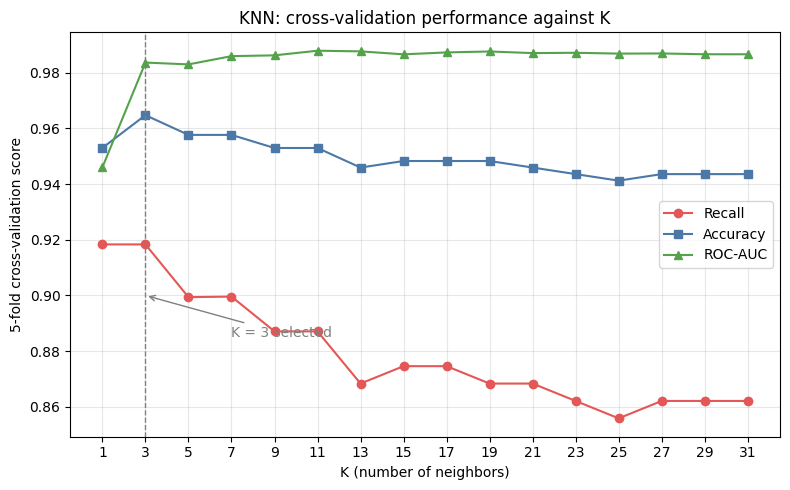

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, cv_recall, marker="o", label="Recall", color="#E45756")
ax.plot(k_values, cv_accuracy, marker="s", label="Accuracy", color="#4C78A8")
ax.plot(k_values, cv_auc, marker="^", label="ROC-AUC", color="#54A24B")
ax.axvline(3, linestyle="--", color="gray", linewidth=1)
ax.annotate("K = 3 selected", xy=(3, 0.90), xytext=(7, 0.885),
            arrowprops=dict(arrowstyle="->", color="gray"), color="gray")
ax.set_xlabel("K (number of neighbors)")
ax.set_ylabel("5-fold cross-validation score")
ax.set_title("KNN: cross-validation performance against K")
ax.set_xticks(k_values)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Which K did I choose, and why?

**K = 3.**

K = 1 and K = 3 are tied on cross-validated recall, both at 0.918. But other metrics help to separate them decisively:

| K | CV Recall | CV Accuracy | CV ROC-AUC |
|---|---|---|---|
| 1 | 0.918 | 0.953 | 0.946 |
| 3 | 0.918 | **0.965** | **0.984** |

If K = 1, each data point classification depends entirely on its nearest neighbor since all points are classified based solely on that one point. This is the most variable option among the choices presented. The ROC-AUCs of 0.946 versus 0.984 illustrate the tradeoff involved: predictions generated by K = 1 give badly calibrated probabilities, since a prediction can be only a 0 or 1 with no in-betweens.

K = 3 matches K = 1 on our top metric, but with better stability and usable probabilities. Recall declines from K = 5 onward, so a larger K is unnecessary.

In [13]:
BEST_K = 3
knn = Pipeline([("scaler", StandardScaler()),
                ("model", KNeighborsClassifier(n_neighbors=BEST_K))])
knn.fit(X_train, y_train)
knn_probs = knn.predict_proba(X_test)[:, 1]
knn_preds = knn.predict(X_test)
print(f"Final KNN fitted with K = {BEST_K}.")

Final KNN fitted with K = 3.


---
# Part 4: Evaluate the Models

All four models are now compared on the **test data**, which has not been touched.

### 4.1 Threshold selection

The following confusion matrices are based on a threshold of **0.50**. This is the default traditional value: a tumor is classified as malignant if the probability of it being malignant from the model exceeds 0.50.

Selecting 0.50 as the threshold is a deliberate choice for the beginning and not the solution itself. It considers a false positive and a false negative to be of equal importance, which Part 1 shows to be incorrect for cancer screening. Selecting 0.50 makes it possible to compare all four models under equal conditions, after which Part 6 addresses the issue of the threshold.

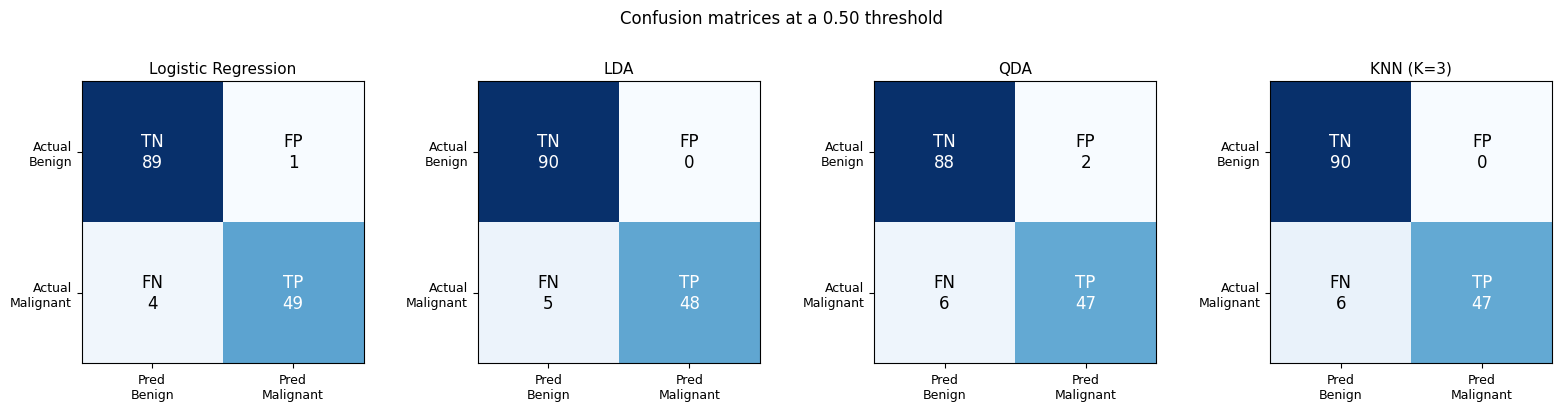

Logistic Regression     TN= 89  FP= 1  FN= 4  TP= 49   <- 4 missed cancers
LDA                     TN= 90  FP= 0  FN= 5  TP= 48   <- 5 missed cancers
QDA                     TN= 88  FP= 2  FN= 6  TP= 47   <- 6 missed cancers
KNN (K=3)               TN= 90  FP= 0  FN= 6  TP= 47   <- 6 missed cancers


In [14]:
model_outputs = {
    "Logistic Regression": (logreg_preds, logreg_probs),
    "LDA": (lda_preds, lda_probs),
    "QDA": (qda_preds, qda_probs),
    f"KNN (K={BEST_K})": (knn_preds, knn_probs),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, (preds, probs)) in zip(axes, model_outputs.items()):
    cm = confusion_matrix(y_test, preds)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred\nBenign", "Pred\nMalignant"], fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual\nBenign", "Actual\nMalignant"], fontsize=9)
    labels = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center",
                    fontsize=12, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.suptitle("Confusion matrices at a 0.50 threshold", y=1.04)
plt.tight_layout(); plt.show()

for name, (preds, probs) in model_outputs.items():
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    print(f"{name:22s}  TN={tn:3d}  FP={fp:2d}  FN={fn:2d}  TP={tp:3d}   <- {fn} missed cancers")

In [15]:
rows = []
for name, (preds, probs) in model_outputs.items():
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probs),
    })

results = pd.DataFrame(rows).set_index("Model")
print("Model comparison on the test set (threshold = 0.50)\n")
print(results.round(4).to_string())

Model comparison on the test set (threshold = 0.50)

                     Accuracy  Precision  Recall  Specificity      F1  ROC-AUC
Model                                                                         
Logistic Regression    0.9650     0.9800  0.9245       0.9889  0.9515   0.9962
LDA                    0.9650     1.0000  0.9057       1.0000  0.9505   0.9960
QDA                    0.9441     0.9592  0.8868       0.9778  0.9216   0.9945
KNN (K=3)              0.9580     1.0000  0.8868       1.0000  0.9400   0.9881


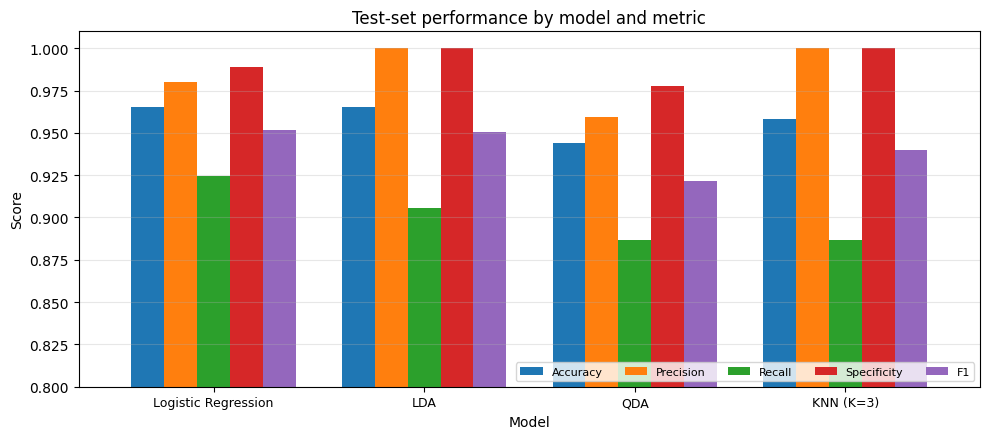

In [16]:
ax = results[["Accuracy", "Precision", "Recall", "Specificity", "F1"]].plot(
    kind="bar", figsize=(10, 4.5), width=0.78)
ax.set_ylim(0.80, 1.01)
ax.set_ylabel("Score")
ax.set_title("Test-set performance by model and metric")
ax.set_xticklabels(results.index, rotation=0, fontsize=9)
ax.legend(loc="lower right", ncol=5, fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

---
# Part 5: Reflect on the Results

### What the table shows

**Logistic Regression and LDA are tied in terms of accuracy at 96.5%, but they achieve the same accuracy in different ways.** Logistic regression fails to diagnose 4 cancers and makes 1 false positive diagnosis. LDA fails to diagnose 5 cancers and makes 0 false positives. The exact same accuracy levels, and when viewed clinically, logistic regression wins the comparison because the additional cancer that it diagnoses is worth more than the one false positive.

This comparison is the strongest example in the entire project of how accuracy is an incorrect headline number.

**Both QDA and KNN err in detecting 6 cancers; however, the two approaches react in entirely different manners otherwise.** While QDA has the greatest number of 2 false positives, the most of any model, its performance is thus the weakest. The reason lies in the approach, because QDA estimates covariance separately for each of the classes, meaning 930 covariance parameters are estimated using 426 observations.

**On the contrary, KNN is the most conservative among the four models.** It has produced no false positives; hence, its precision and specificity equal 1.000, whereas accuracy reaches 95.8%, exceeding that of QDA. However, reaching such a high level of specificity was achieved at the cost of 6 missed cases of cancer, which is precisely the error we seek to avoid.

### Which metrics are informative here

The first part proved that a false negative case has much higher cost than a false positive. This gives us an answer to the ordering of the metrics:

**Recall is the first metric to care about.** This tells us how many true malignant masses out of all truly malignant were captured by the algorithm. The best result was given by logistic regression, which has 0.925 recall.

**Second, ROC-AUC** is a useful metric, because it tells us how well the model ranks malignant masses higher than benign ones for any threshold. This is important, because, as the 6th part proves, we do not intend to use the 0.50 threshold anymore.

**Specificity and precision merit consideration, but shouldn’t be decisive factors.** These measures capture the false alarm cost, which is a legitimate concern but a recoupable one.

**Accuracy and F1 score provide the least insight.** Both metrics make no distinction between the two kinds of errors. F1 score is the harmonic mean of precision and recall, and hence assumes the two measures to be of equal importance, which clearly is not the case.

---
# Part 6: ROC Curves and Threshold Analysis

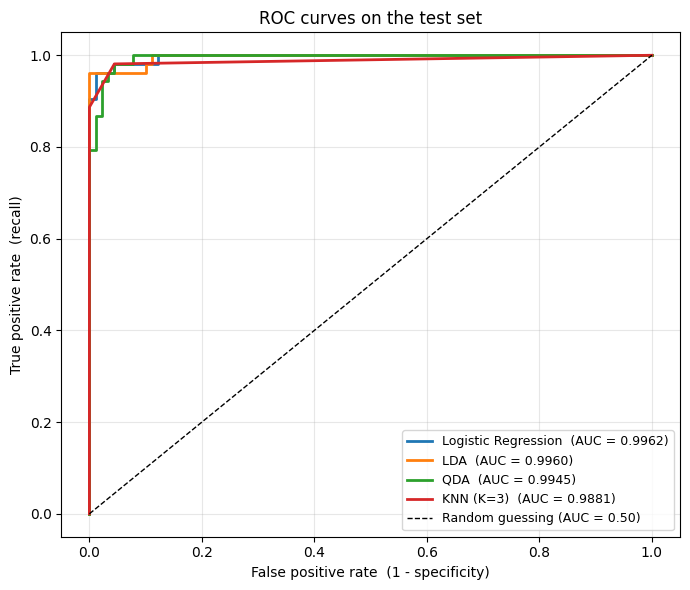

ROC-AUC by model:
  Logistic Regression    0.9962
  LDA                    0.9960
  QDA                    0.9945
  KNN (K=3)              0.9881


In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, (preds, probs) in model_outputs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, linewidth=2, label=f"{name}  (AUC = {roc_auc_score(y_test, probs):.4f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guessing (AUC = 0.50)")
ax.set_xlabel("False positive rate  (1 - specificity)")
ax.set_ylabel("True positive rate  (recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("ROC-AUC by model:")
for name, (preds, probs) in model_outputs.items():
    print(f"  {name:22s} {roc_auc_score(y_test, probs):.4f}")

### What ROC-AUC tells us, in plain terms

In the ROC curve, the relationship between the number of cancers detected and the number of false positives is measured for different values of the decision threshold ranging from high to low. Each point on the graph corresponds to a single threshold value.

**The AUC of the ROC is the area under the ROC, and it can be interpreted as follows: if you choose randomly an example of a malignant mass and a benign mass, then the AUC represents the probability of assigning a greater malignancy score to the first mass.**

Logistic Regression has an AUC of 0.9962, which implies that if you select randomly an example of a malignant and benign mass, Logistic Regression will correctly rank them 99.6% of the time.

It matters because **this metric is independent of the threshold**. While the accuracy, precision and recall metrics describe the performance at one specific threshold value, AUC measures how well is the underlying ranking. This means that AUC helps us find out whether a classifier has actually learned the classes distribution or it looks good at 0.50 by pure luck.

This becomes particularly clear when we analyze KNN performance. Despite having accuracy of 95.8%, which is the third highest of the four classifiers, KNN AUC equals 0.9881, being the lowest. It can be easily explained from the picture of its ROC curve, which is much more angular compared to the ROC curves of the other models. For example, with K = 3 a predicted probability for KNN could take either 0, 0.33, 0.67 or 1 values, thus there are 4 scores, and ordering within these groups is arbitrary.

In [18]:
print("Logistic regression at different thresholds\n")
print(f"{'Threshold':>10} {'FN':>4} {'FP':>4} {'Recall':>9} {'Precision':>10} {'Specificity':>12}")
print("-" * 56)
for t in [0.60, 0.50, 0.40, 0.30, 0.20, 0.10]:
    preds_t = (logreg_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_t).ravel()
    print(f"{t:>10.2f} {fn:>4d} {fp:>4d} {recall_score(y_test, preds_t):>9.4f} "
          f"{precision_score(y_test, preds_t):>10.4f} {tn/(tn+fp):>12.4f}")

Logistic regression at different thresholds

 Threshold   FN   FP    Recall  Precision  Specificity
--------------------------------------------------------
      0.60    5    0    0.9057     1.0000       1.0000
      0.50    4    1    0.9245     0.9800       0.9889
      0.40    3    1    0.9434     0.9804       0.9889
      0.30    2    1    0.9623     0.9808       0.9889
      0.20    2    3    0.9623     0.9444       0.9667
      0.10    1    6    0.9811     0.8966       0.9333


### The threshold finding

This is the most actionable finding in the project.

**Decreasing the threshold from 0.50 to 0.30 will decrease the number of missed tumors from 4 to 2 while keeping the number of false positives at 1.** This change is cost-free and two more women with malignant masses will be detected while nobody else will be wrongly referred to undergo an unnecessary biopsy.

Going even lower to 0.20 does not help and produces two more false positives. Thus, 0.30 is the point of zero gains.

None of the parameters in the model was changed from one row to another. All the coefficients remained the same as well as no refitting was done. All that was changed was the decision rule which converts probability into a classification outcome. Since it has been shown in Part 1 that the major cost of the procedure is in false negatives, **0.30 is the optimal threshold to use for this model**.

---
# Part 7: Final Analysis

### 7.1 How the four classifiers compare

Each model works. The least successful one classifies 94% of all masses properly, which means this is not the case of success for one model and failure for all others. They only differ by **what mistakes they do**.

**Logistic regression recognizes the most cancers.** On 143 test masses, logistic regression misses 4 out of 53 cancerous masses and incorrectly labels 1 benign mass.

**LDA is almost the same and a little bit more cautious.** LDA doesn’t give any false positives, but it misses 5 cancers instead of 4. These two models have absolutely identical accuracies of 96.5%, which is a perfect example of why an accuracy measure tells less than it seems to tell.

**Six cancers were missed by QDA and KNN.** QDA performed worse compared to others because it also gave the highest number of false positives. It is more flexible than LDA and, as a result, requires a greater number of parameters which cannot be estimated correctly due to 426 observations in the training set. On the contrary, KNN was the most conservative of four models because it did not make a single mistake on benign masses. However, it also missed two more cancers compared to logistic regression.

The key difference is the ability to calculate probabilities instead of just classification labels. The probability estimates calculated by logistic regression, LDA and QDA models gave an AUC value higher than 0.994. Meanwhile, KNN has 0.988 AUC value although it is highly accurate. KNN can give you its decision, but it cannot evaluate its confidence level because it has four confidence levels with three neighbors.

### 7.2 Which model I would deploy

**Logistic Regression, with the threshold for making decisions set at 0.30 instead of the standard 0.50.**

This method detects the largest number of cancer cases among all four models. Recall rate is important in the problem considered here since it is about detecting as many cancer cases as possible.

It provides reliable probabilities; the AUC metric equals 0.9962 and is larger than that of other three models. This allows for threshold adjustment, and changing it from 0.50 to 0.30 decreases the number of undetected cancer cases by 2 without increasing the number of false positives. It would be impossible to make this change for KNN, since it provides only four different probability values.

The model is interpretable. All predictors have coefficients with signs and magnitudes, meaning that a doctor can see what the model relies on. This is not a negligible property for medicine since no one uses a black box approach.

Of course, the fair admission is that LDA is so close that the margin can easily be reversed for a different sample. I'm not saying that logistic regression is innately superior; rather, I'm saying that, in this particular data set, it makes the right choice and there's nothing more difficult about it.

### 7.3 One limitation

**The test set includes only 53 malignant tumors.**

All of the recall values mentioned above are based on this value. The difference between logistic regression and LDA values, which are 0.925 and 0.906 respectively, is only one person. If one patient was included in the other category, the order of the algorithms would be different.

It seems like an insufficient foundation for claiming that one algorithm outperforms the other. The overall conclusion is valid: the measurements contain a lot of useful information and all four algorithms extract it; however, the relative performance of the algorithms is not reliably established based on 143 test observations.

Another constraint is the fact that the data originates from a single source and the images have been processed the same way. The performance of the model on images produced by different equipment and laboratories has not been verified.

### 7.4 What I would want before real-world use

**A much larger and more varied validation sample**, coming from a wide variety of hospitals equipped with different imaging technology and a patient population similar to the population where the model will be used. Performance on data from one hospital does not tell us much about performance on data from other hospitals.

**The cost ratio of the two errors.** The entire case for choosing a particular threshold depends on the fact that false negatives are worse than false positives, which is clearly true in principle, but I chose 0.30 by looking at the table, not by any rigorous calculation. Medical experts and health economists can describe the cost ratio in quantitative terms.

**Patient outcome information, not only disease diagnoses.** The knowledge that a tumor is malignant is not equivalent to the outcome of what happened to the patient. A system that detects aggressive cancer cases early on is worth more than one that detects mostly non-aggressive cancers with the same recall rate.

**Confirmation that the predictor values remain available and comparable.** All 30 of these variables come from a particular image analysis pipeline. If another place runs a different calculation for any of these variables, the system does not transfer.

In [19]:
print("=" * 68)
print("SUMMARY")
print("=" * 68)
print(results.round(4).to_string())
print()
print(f"Selected model:     Logistic Regression")
print(f"Selected threshold: 0.30")
preds_final = (logreg_probs >= 0.30).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, preds_final).ravel()
print(f"\nAt the deployed threshold of 0.30 on {len(y_test)} test masses:")
print(f"  Cancers caught:  {tp} of {tp+fn}")
print(f"  Cancers missed:  {fn}")
print(f"  False alarms:    {fp}")
print(f"  Recall:          {recall_score(y_test, preds_final):.4f}")
print(f"  Specificity:     {tn/(tn+fp):.4f}")

SUMMARY
                     Accuracy  Precision  Recall  Specificity      F1  ROC-AUC
Model                                                                         
Logistic Regression    0.9650     0.9800  0.9245       0.9889  0.9515   0.9962
LDA                    0.9650     1.0000  0.9057       1.0000  0.9505   0.9960
QDA                    0.9441     0.9592  0.8868       0.9778  0.9216   0.9945
KNN (K=3)              0.9580     1.0000  0.8868       1.0000  0.9400   0.9881

Selected model:     Logistic Regression
Selected threshold: 0.30

At the deployed threshold of 0.30 on 143 test masses:
  Cancers caught:  51 of 53
  Cancers missed:  2
  False alarms:    1
  Recall:          0.9623
  Specificity:     0.9889
